<a href="https://colab.research.google.com/github/Matlosa11/Matlosa_Repository/blob/main/Matlosa_Week4_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

# Import the libraries
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt

# Load the mining equipment dataset
dataset = load_dataset(
    "electricsheepafrica/africa-synth-mining-equipment-failure-all"
)

# Convert the first dataset split into a DataFrame
split_name = next(iter(dataset))
df = dataset[split_name].to_pandas()

# Display the first five rows
display(df.head())

# Check the available columns
print("Available columns:")
print(df.columns.tolist())


,record_id,equipment_id,equipment_type,manufacturer,model_year,mine_type,country,operating_hours,event_date,event_type,...,severity,downtime_hours,repair_cost_usd,production_loss_tonnes,maintenance_type,was_scheduled,days_since_last_service,oil_analysis_flag,vibration_flag,temperature_flag
0,EQP-ADB3590D,UNIT-1803,haul_truck,Caterpillar,2008,underground,drc,64584,2022-12-03,breakdown,...,major,17.4,70862.60,1711.0,corrective,False,27,False,False,False
1,EQP-596EE017,UNIT-7964,crusher,Sandvik,2019,open_pit,botswana,19253,2023-08-03,breakdown,...,major,46.3,74513.34,10010.0,corrective,False,57,True,False,False
2,EQP-23341C24,UNIT-6890,pump,Metso,2011,open_pit,south_africa,52894,2020-05-28,breakdown,...,major,10.7,17661.80,580.0,corrective,False,107,False,False,False
3,EQP-D8EF5309,UNIT-4949,loader,Volvo,2019,processing_plant,zambia,18369,2024-11-21,condition_based,...,routine,2.5,2218.70,240.0,predictive,False,23,False,True,False
4,EQP-5A611650,UNIT-4896,excavator,Hitachi,2017,underground,ghana,27901,2022-12-30,condition_based,...,minor,7.7,36773.60,1468.0,predictive,False,57,False,False,False


Available columns:
['record_id', 'equipment_id', 'equipment_type', 'manufacturer', 'model_year', 'mine_type', 'country', 'operating_hours', 'event_date', 'event_type', 'failure_mode', 'component_failed', 'severity', 'downtime_hours', 'repair_cost_usd', 'production_loss_tonnes', 'maintenance_type', 'was_scheduled', 'days_since_last_service', 'oil_analysis_flag', 'vibration_flag', 'temperature_flag']


In [3]:

# Select the numerical variables for the analysis
variables = [
    "operating_hours",
    "downtime_hours",
    "repair_cost_usd",
    "production_loss_tonnes"
]

# Check that all selected columns exist
missing_columns = [col for col in variables if col not in df.columns]

if missing_columns:
    raise ValueError(f"Columns not found in dataset: {missing_columns}")

# Convert the selected columns to numeric values
data = df[variables].apply(pd.to_numeric, errors="coerce")

# Remove rows with missing values in these variables
data = data.dropna()

# Display the selected data
display(data.head())

print("Number of complete records:", len(data))


,operating_hours,downtime_hours,repair_cost_usd,production_loss_tonnes
0,64584,17.4,70862.60,1711.0
1,19253,46.3,74513.34,10010.0
2,52894,10.7,17661.80,580.0
3,18369,2.5,2218.70,240.0
4,27901,7.7,36773.60,1468.0


Number of complete records: 5000


In [4]:

# Calculate descriptive statistics for each variable
statistics = pd.DataFrame({
    "Mean": data.mean(),
    "Median": data.median(),
    "Range": data.max() - data.min(),
    "Variance": data.var(),
    "Standard Deviation": data.std()
})

# Display the results rounded to two decimal places
display(statistics.round(2))


,Mean,Median,Range,Variance,Standard Deviation
operating_hours,33820.15,33299.00,66213.00,3.416296e+08,18483.22
downtime_hours,11.88,6.30,235.10,2.820200e+02,16.79
repair_cost_usd,26066.37,9822.81,594335.02,2.124092e+09,46087.88
production_loss_tonnes,1679.09,631.50,49905.00,1.022074e+07,3196.99


In [5]:

# Select the two variables for comparison
x = data["operating_hours"]
y = data["downtime_hours"]

# Calculate covariance and Pearson correlation
covariance = x.cov(y)
correlation = x.corr(y)

print(f"Covariance: {covariance:.4f}")
print(f"Correlation coefficient: {correlation:.4f}")


Covariance: -2888.2923
Correlation coefficient: -0.0093


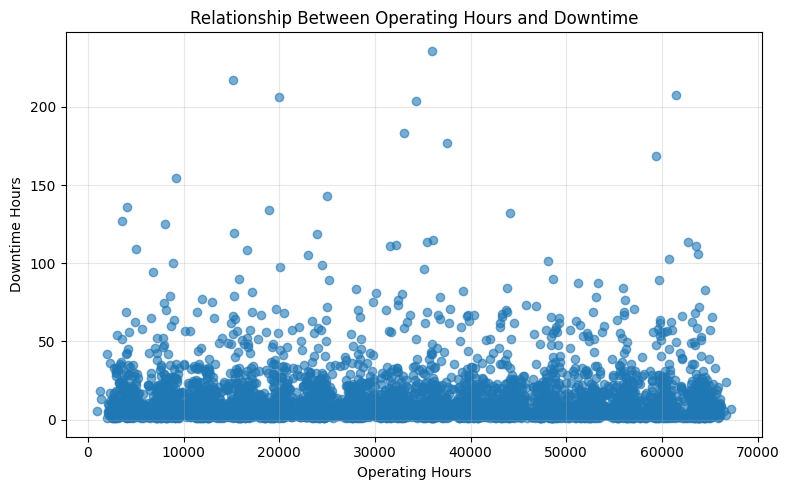

In [6]:

# Plot the relationship between operating hours and downtime
plt.figure(figsize=(8, 5))
plt.scatter(
    data["operating_hours"],
    data["downtime_hours"],
    alpha=0.6
)

plt.xlabel("Operating Hours")
plt.ylabel("Downtime Hours")
plt.title("Relationship Between Operating Hours and Downtime")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

## Interpretation of Statistical Results

### 1. What do the statistics tell you about the data?

The mean represents the average value of each variable, while the median represents its middle value. Comparing these two measures can indicate whether the data may be skewed by unusually large or small observations.

The range shows the difference between the highest and lowest values. Variance and standard deviation measure how widely the observations are spread around the mean.

The statistics help describe the variability in equipment operating hours, downtime, repair costs, and production losses. Large standard deviations or ranges indicate substantial differences between records. These differences may be important when investigating mining equipment reliability and production interruptions.

### 2. What does the correlation tell you about the relationship between the two variables?

The Pearson correlation coefficient between operating hours and downtime hours was **[insert your calculated correlation]**.

This indicates a **[positive / negative / weak]** linear relationship between the two variables. The scatter plot helps show whether this relationship is visible in the data and whether unusual observations may influence it.

Understanding this relationship may help guide further research into equipment reliability and operational interruptions. However, this dataset contains synthetic records and does not establish the relationship for continuous miners or shuttle cars at Morupule Coal Mine.

### 3. Does correlation necessarily mean that one variable causes the other?

No. Correlation does not necessarily imply causation. Even if operating hours and downtime are correlated, this does not prove that one directly causes the other.

Other factors, such as equipment age, maintenance history, operating conditions, equipment type, and failure severity, may influence downtime. Further investigation and appropriate research methods would be needed to establish causal relationships.


In [ ]:

## Mathematical Representation of the Input-Output Relationship

For this analysis, operating hours are selected as the input variable, while downtime hours are selected as the output variable.

The relationship can be represented as:

\[
X \rightarrow f(X) \rightarrow \hat{Y}
\]

Where:

- \(X\) = Equipment operating hours
- \(f\) = A mathematical function or machine learning model
- \(\hat{Y}\) = Predicted downtime hours

A simple linear model can be expressed as:

\[
\hat{Y} = \beta_0 + \beta_1 X
\]

Where \(\beta_0\) is the intercept and \(\beta_1\) is the coefficient representing the estimated change in downtime associated with a one-unit increase in operating hours.

This expression illustrates how equipment operating data could be used to estimate downtime. The coefficients would need to be estimated from data, and the model would need to be evaluated before it could be used for prediction.
